# 00 — Loading Qwen3.5-4B and looking inside

## 1. Tokenizer

In [1]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL = "Qwen/Qwen3.5-4B"
tokenizer = AutoTokenizer.from_pretrained(MODEL)

text = "She read the letter and burst into tears."
ids = tokenizer(text)["input_ids"]   # a plain Python list of token IDs

for position, token_id in enumerate(ids):
    print(position, token_id, repr(tokenizer.decode(token_id)))

0 7691 'She'
1 1301 ' read'
2 279 ' the'
3 6321 ' letter'
4 321 ' and'
5 19899 ' burst'
6 1083 ' into'
7 22417 ' tears'
8 13 '.'


no start or end token , these are added with the chat template. so the first token is the real word

In [2]:
print(tokenizer("read")["input_ids"])
print(tokenizer(" read")["input_ids"])

[851]
[1301]


so this means we could have the same word but encoded in different tokens depending on capitalization, spacing , etc.. ! 

## 2. Load model + sanity check

In [3]:
model = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.bfloat16).to("mps")
model.eval()

print(torch.mps.current_allocated_memory() / 1e9, "GB")

8.415182336 GB


In [4]:
print(model)

Qwen3_5ForCausalLM(
  (model): Qwen3_5TextModel(
    (embed_tokens): Embedding(248320, 2560)
    (layers): ModuleList(
      (0-2): 3 x Qwen3_5DecoderLayer(
        (linear_attn): Qwen3_5GatedDeltaNet(
          (conv1d): Conv1d(8192, 8192, kernel_size=(4,), stride=(1,), padding=(3,), groups=8192, bias=False)
          (norm): Qwen3_5RMSNormGated()
          (out_proj): Linear(in_features=4096, out_features=2560, bias=False)
          (in_proj_qkv): Linear(in_features=2560, out_features=8192, bias=False)
          (in_proj_z): Linear(in_features=2560, out_features=4096, bias=False)
          (in_proj_b): Linear(in_features=2560, out_features=32, bias=False)
          (in_proj_a): Linear(in_features=2560, out_features=32, bias=False)
        )
        (mlp): Qwen3_5MLP(
          (gate_proj): Linear(in_features=2560, out_features=9216, bias=False)
          (up_proj): Linear(in_features=2560, out_features=9216, bias=False)
          (down_proj): Linear(in_features=9216, out_features=256

In [5]:
prompt = "She read the letter and burst into"
inputs = tokenizer(prompt, return_tensors="pt").to("mps")

with torch.inference_mode():
    out_ids = model.generate(**inputs, max_new_tokens=10, do_sample=False)  # greedy: always the most likely token (loops if you let it run long)

print(tokenizer.decode(out_ids[0]))

She read the letter and burst into tears.
The letter was from her mother.


## 3. Hidden states

In [6]:
inputs = tokenizer(text, return_tensors="pt").to("mps")

with torch.inference_mode():
    outputs = model(**inputs, output_hidden_states=True)

hs = outputs.hidden_states
print(len(hs), hs[21].shape)

33 torch.Size([1, 9, 2560])


In [7]:
emb = model.model.embed_tokens(inputs["input_ids"])
print(torch.allclose(hs[0], emb))

True


ok 1 is because one text ( batch of size one), 9 is the number of tokens we counted , and for every token we have a 2560 at each layer

**Convention:** layer L = `hs[L]` = the residual stream after L layers. `hs[0]` = embeddings, so `hs[i + 1]` = output of `model.model.layers[i]`.

## 4. Residual norm per layer

In [8]:
for layer, h in enumerate(hs):
    vectors = h[0].float()            # [tokens, 2560], in fp32 before squaring and summing
    norms = vectors.norm(dim=-1)      # the length of each token's vector
    print(layer, [round(n) for n in norms.tolist()])

0 [1, 1, 1, 1, 1, 1, 1, 1, 1]
1 [2, 2, 2, 3, 2, 3, 2, 3, 2]
2 [3, 3, 3, 3, 3, 3, 3, 3, 2]
3 [6, 4, 3, 4, 3, 4, 3, 3, 3]
4 [5, 5, 5, 5, 4, 5, 5, 5, 4]
5 [6, 6, 5, 6, 5, 6, 6, 6, 5]
6 [6, 7, 6, 7, 6, 7, 8, 6, 6]
7 [28, 9, 8, 8, 7, 8, 9, 8, 7]
8 [19, 9, 8, 8, 7, 9, 8, 8, 7]
9 [18, 9, 8, 8, 8, 9, 9, 9, 7]
10 [18, 10, 9, 9, 8, 10, 9, 10, 8]
11 [25, 10, 9, 10, 9, 11, 10, 11, 9]
12 [23, 10, 10, 10, 9, 10, 10, 10, 9]
13 [22, 11, 10, 10, 9, 10, 10, 10, 9]
14 [22, 11, 10, 11, 10, 10, 11, 11, 9]
15 [23, 12, 10, 12, 11, 12, 11, 13, 11]
16 [18, 12, 10, 12, 11, 11, 11, 12, 11]
17 [17, 12, 10, 12, 11, 11, 11, 12, 11]
18 [16, 12, 11, 13, 13, 12, 12, 13, 12]
19 [47, 14, 14, 16, 15, 15, 14, 18, 14]
20 [14, 16, 16, 17, 18, 16, 16, 18, 15]
21 [15, 18, 18, 20, 20, 20, 18, 19, 17]
22 [16, 21, 21, 22, 22, 22, 21, 24, 21]
23 [21, 27, 26, 28, 27, 25, 24, 27, 40]
24 [22, 28, 28, 29, 29, 25, 25, 27, 26]
25 [24, 31, 32, 31, 32, 28, 28, 30, 29]
26 [27, 34, 37, 33, 36, 30, 31, 32, 36]
27 [33, 41, 45, 40, 46, 35, 36

## 5. What is hs[32]?

In [9]:
# A forward hook is a function PyTorch calls every time a module runs.
# We use one to grab the RAW output of the last layer, before the final norm.
captured = []

def save_output(module, inp, output):
    captured.append(output)

handle = model.model.layers[31].register_forward_hook(save_output)
with torch.inference_mode():
    model(**inputs)
handle.remove()   # always remove hooks, or they fire on every future forward pass

raw = captured[0]
print("norm of raw last-layer output:", round(raw[0].float().norm(dim=-1).mean().item(), 1))
print("norm of hs[32]               :", round(hs[32][0].float().norm(dim=-1).mean().item(), 1))

with torch.inference_mode():
    print("hs[32] == final_norm(raw)?   ", torch.allclose(hs[32], model.model.norm(raw)))

norm of raw last-layer output: 67.4
norm of hs[32]               : 155.3
hs[32] == final_norm(raw)?    True


## 6. Attention sink

An **attention sink** is a token that many other tokens attend to heavily, not because it's relevant but because attention weights must add up to 1. Heads with "nothing useful to look at" park their attention somewhere, and that's usually position 0.

Two signatures: (1) lots of attention on position 0, (2) an unusually large norm at position 0.

In [10]:
story = ("Maria had waited three years for this letter. When it finally arrived, she sat at the kitchen table "
         "and read it slowly, twice, her hands shaking. Her brother was coming home. She folded the paper, "
         "pressed it to her chest, and for the first time in months she laughed out loud.")
story_inputs = tokenizer(story, return_tensors="pt").to("mps")
n_tokens = story_inputs["input_ids"].shape[1]

# The fast default attention never builds the attention matrix, so switch to "eager" for this one pass
model.set_attn_implementation("eager")
with torch.inference_mode():
    story_out = model(**story_inputs, output_attentions=True, output_hidden_states=True)
model.set_attn_implementation("sdpa")

attentions = story_out.attentions          # only the 8 full-attention layers have an attention matrix
full_layers = [3, 7, 11, 15, 19, 23, 27, 31]
print(len(attentions), attentions[0].shape)  # [batch, heads, query, key]

8 torch.Size([1, 16, 60, 60])


In [11]:
# If token q spread its attention evenly over the q+1 tokens it can see, position 0 would get 1/(q+1)
even_share = sum(1 / (q + 1) for q in range(1, n_tokens)) / (n_tokens - 1)

for layer, att in zip(full_layers, attentions):
    to_first = att[0, :, 1:, 0].float()    # all heads, all queries except token 0, key = position 0
    share = to_first.mean().item()
    print(layer, "attention on position 0:", round(share, 2), "=", round(share / even_share, 1), "x even spread")

3 attention on position 0: 0.11 = 1.7 x even spread
7 attention on position 0: 0.15 = 2.4 x even spread
11 attention on position 0: 0.15 = 2.5 x even spread
15 attention on position 0: 0.26 = 4.1 x even spread
19 attention on position 0: 0.24 = 3.8 x even spread
23 attention on position 0: 0.04 = 0.7 x even spread
27 attention on position 0: 0.05 = 0.8 x even spread
31 attention on position 0: 0.04 = 0.6 x even spread


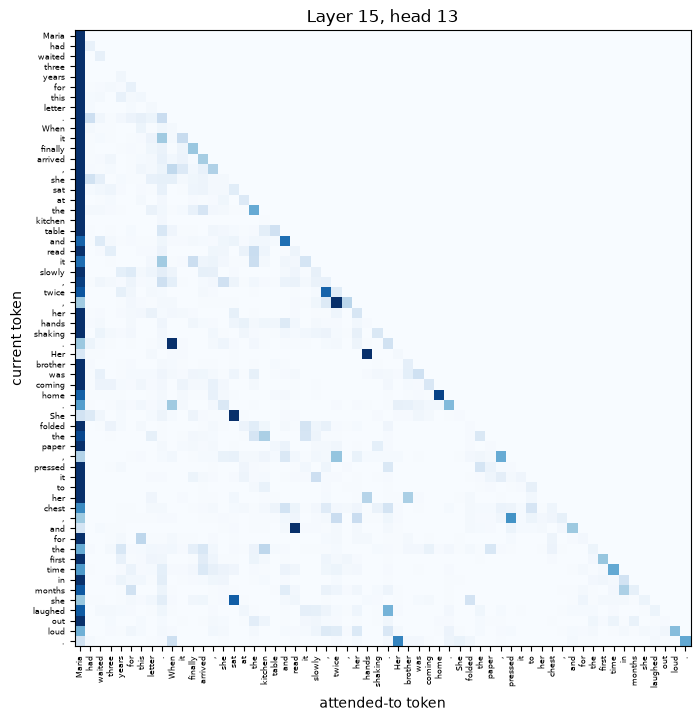

In [12]:
import matplotlib.pyplot as plt

att15 = attentions[full_layers.index(15)][0].float()   # layer 15: [heads, query, key]
head = att15[:, 1:, 0].mean(dim=1).argmax().item()     # the head that attends most to position 0

labels = [tokenizer.decode(t) for t in story_inputs["input_ids"][0]]
plt.figure(figsize=(9, 8))
plt.imshow(att15[head].cpu(), cmap="Blues", vmax=0.5)
plt.xticks(range(n_tokens), labels, rotation=90, fontsize=6)
plt.yticks(range(n_tokens), labels, fontsize=6)
plt.xlabel("attended-to token")
plt.ylabel("current token")
plt.title(f"Layer 15, head {head}")
plt.show()

In [13]:
for layer in [4, 8, 12, 16, 19, 20, 24, 28, 31]:
    norms = story_out.hidden_states[layer][0].float().norm(dim=-1)
    print(layer, "position 0:", round(norms[0].item()), "| median of the others:", round(norms[1:].median().item()))

4 position 0: 5 | median of the others: 5
8 position 0: 17 | median of the others: 8
12 position 0: 23 | median of the others: 10
16 position 0: 18 | median of the others: 11
19 position 0: 47 | median of the others: 14
20 position 0: 14 | median of the others: 17
24 position 0: 23 | median of the others: 28
28 position 0: 29 | median of the others: 40
31 position 0: 47 | median of the others: 54
